# ДЗ 2. Модели оценки недвижимости в новостройках Санкт-Петербурга

Продолжение исправленного ДЗ 1: прогноз **цены предложения в рублях** по характеристикам объявления. Исходные данные собраны в декабре 2024 года; единица наблюдения — объявление. Решение может помочь сравнить предложение с похожими объектами, но не оценивает цену сделки.

Сравню медиану, среднее, Ridge на трёх площадях, Ridge на полном наборе и Random Forest. Основной критерий — **MAE**, дополнительный — **RMSE**: вторая метрика сильнее реагирует на крупные промахи в дорогом хвосте. Обе считаются в рублях, включая модели с логарифмом цели. Победителя выбираю по средней тренировочной CV MAE; тест нужен для итоговой оценки, а не выбора модели.

Два протокола отвечают на разные вопросы: случайное разбиение объявлений оценивает работу на похожей смеси ЖК, групповое — перенос на ЖК, которых не было в обучении. Это альтернативные разбиения одного исторического набора, а не две независимые внешние выборки. Весь набор уже рассматривался в EDA ДЗ 1; для внешней проверки нужны новые данные.

## 1. Среда и загрузка

Ноутбук сам читает Excel и не запускает ДЗ 1. Требуются Python 3.12 и `requirements-hw2.txt`. Например, из корня проекта:

```powershell
python -m venv "$env:TEMP\ftmi-hw2-venv"
& "$env:TEMP\ftmi-hw2-venv\Scripts\python.exe" -m pip install -r HW/requirements-hw2.txt
& "$env:TEMP\ftmi-hw2-venv\Scripts\python.exe" -m ipykernel install --user --name ftmi-hw2 --display-name "Python (FTMI HW2)"
```

Выбрать ядро этой среды и выполнить **Restart Kernel and Run All Cells**. Рабочий каталог — корень проекта или `HW/`; из `HW/` путь к requirements не содержит префикса `HW/`. Сеть при выполнении ноутбука не нужна. Поиск использует две параллельные задачи, каждый лес — один поток; выполнение может занять несколько минут.

In [1]:
%matplotlib inline

import hashlib
import importlib.metadata as metadata
import os
from pathlib import Path
import platform
import random
import time

for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd
import shap
from IPython.display import Markdown, display
from joblib import parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    GroupShuffleSplit,
    KFold,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.18,
    }
)

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "shap",
    "numba",
    "llvmlite",
    "matplotlib",
    "openpyxl",
    "joblib",
    "threadpoolctl",
    "IPython",
    "ipykernel",
    "ipywidgets",
    "nbformat",
    "nbclient",
    "nbconvert",
]
versions = {"Python": platform.python_version()}
versions.update({name: metadata.version(name) for name in packages})
display(pd.Series(versions, name="Версия").to_frame())


def find_data_path():
    """Относительный путь из HW/ или корня репозитория."""
    for candidate in [
        Path("data/cian_spb.xlsx"),
        Path("HW/data/cian_spb.xlsx"),
    ]:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError("Запустите ноутбук из HW/ или корня проекта.")


DATA_PATH = find_data_path()
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert source_hash == (
    "795605d2e2ad8316d5b3ba92a2c62353bb237a5ff9fcd0bb8708620599252b3e"
)
raw = pd.read_excel(DATA_PATH, sheet_name="Квартиры СПБ", engine="openpyxl")
print(f"Файл: {DATA_PATH.as_posix()}; SHA-256: {source_hash}")
print(f"Исходная таблица: {raw.shape}")

,Версия
Python,3.12.7
numpy,1.26.4
pandas,2.2.3
scipy,1.15.3
scikit-learn,1.6.1
shap,0.47.2
numba,0.61.2
llvmlite,0.44.0
matplotlib,3.10.3
openpyxl,3.1.5


Файл: data/cian_spb.xlsx; SHA-256: 795605d2e2ad8316d5b3ba92a2c62353bb237a5ff9fcd0bb8708620599252b3e
Исходная таблица: (1400, 21)


## 2. Подготовка по правилам ДЗ 1

Оставляю первую запись каждого непустого URL в порядке Excel. Необязательные пропуски, все типы жилья и дорогие объекты сохраняю. Пропущенные URL, если появятся, не объединяются. Разбор единиц, комнатности и района детерминирован и не использует цену или статистики выборки. Студия кодируется как 0 комнат с отдельным двоичным флагом; для многокомнатных объектов и свободной планировки точное число комнат остаётся неизвестным. Район извлекается только после `р-н`, отделка «Неизвестно» становится пропуском.

Ниже — короткий журнал подготовки вместо повторного EDA. Исходные текстовые поля остаются в таблице для аудита, но в модель попадёт только явный разрешённый список.

In [2]:
LINK = "Ссылка на страницу"
AREA_MAPPING = {
    "Общая площадь": "Общая площадь, м²",
    "Жилая площадь": "Жилая площадь, м²",
    "Площадь кухни": "Площадь кухни, м²",
}


def parse_measure(source, unit_pattern):
    """Разобрать всю строку с десятичной запятой и единицей измерения."""
    normalized = source.astype("string").str.replace("\u00a0", " ").str.strip()
    pattern = rf"^([+-]?[0-9]+(?:[.,][0-9]+)?)\s*(?:{unit_pattern})?$"
    values = normalized.str.extract(pattern, expand=False)
    values = values.str.replace(",", ".", regex=False)
    return pd.to_numeric(values, errors="coerce").astype("Float64")


def prepare_data(source):
    """Правила ДЗ 1: первая ссылка, детерминированный разбор, без фильтра хвоста."""
    removed = source[LINK].notna() & source.duplicated(LINK, keep="first")
    frame = source.loc[~removed].copy()
    frame.insert(0, "Строка Excel", frame.index + 2)
    audit = []

    def record(original, parsed, name):
        audit.append(
            {
                "Признак": name,
                "Пропуски источника": int(original.isna().sum()),
                "Непустые не распознаны": int(
                    (original.notna() & parsed.isna()).sum()
                ),
                "Пропуски результата": int(parsed.isna().sum()),
            }
        )

    for original, parsed in AREA_MAPPING.items():
        frame[parsed] = parse_measure(frame[original], r"м²|м2")
        record(frame[original], frame[parsed], parsed)
    frame["Потолки, м"] = parse_measure(frame["Высота потолков"], r"м")
    record(frame["Высота потолков"], frame["Потолки, м"], "Потолки, м")

    floors = (
        frame["Этаж"]
        .astype("string")
        .str.extract(r"^\s*(\d+)\s+из\s+(\d+)\s*$")
    )
    for position, name in enumerate(["Этаж, число", "Этажность"]):
        frame[name] = pd.to_numeric(floors[position], errors="coerce").astype(
            "Int64"
        )
        record(frame["Этаж"], frame[name], name)

    title = frame["Название"].astype("string").str.lower().str.strip()
    studio = title.str.match(r"^(?:апартаменты-)?студия\b", na=False)
    rooms = pd.to_numeric(
        title.str.extract(r"^(\d+)-комн\.", expand=False), errors="coerce"
    )
    multi = title.str.startswith("многокомнатная", na=False)
    free = title.str.startswith("квартира свободной планировки", na=False)
    frame["Комнат"] = rooms.mask(studio, 0).astype("Int64")
    frame["Студия"] = pd.Series(pd.NA, index=frame.index, dtype="boolean")
    frame.loc[rooms.notna() | multi | free, "Студия"] = False
    frame.loc[studio, "Студия"] = True
    frame["Комнатность"] = frame["Комнат"].astype("string").add("-комнатная")
    frame.loc[studio, "Комнатность"] = "Студия"
    frame.loc[multi, "Комнатность"] = "Многокомнатная"
    frame.loc[free, "Комнатность"] = "Свободная планировка"
    for name in ["Комнат", "Студия", "Комнатность"]:
        record(frame["Название"], frame[name], name)

    frame["Район"] = (
        frame["Адрес"]
        .astype("string")
        .str.extract(r"р-н\s+([^\s,]+)", expand=False)
    )
    record(frame["Адрес"], frame["Район"], "Район")
    frame["Категория жилья"] = (
        frame["Тип жилья"]
        .map(
            {
                "Новостройка": "Квартира",
                "Новостройка Апартаменты": "Апартаменты",
                "Новостройка Пентхаус": "Пентхаус",
            }
        )
        .astype("string")
    )
    frame["Отделка, категория"] = (
        frame["Отделка"].astype("string").replace("Неизвестно", pd.NA)
    )
    frame["Доля этажа"] = frame["Этаж, число"] / frame["Этажность"].where(
        frame["Этажность"] > 0
    )
    frame["Первый этаж"] = frame["Этаж, число"].eq(1)
    frame["Последний этаж"] = frame["Этаж, число"].eq(frame["Этажность"])
    return frame, pd.DataFrame(audit).set_index("Признак"), int(removed.sum())


df, parse_audit, n_removed = prepare_data(raw)
display(
    pd.DataFrame(
        {
            "Этап": [
                "Исходный Excel",
                "Первая запись на URL",
                "Разбор признаков",
            ],
            "Осталось": [len(raw), len(df), len(df)],
            "Удалено": [0, n_removed, 0],
        }
    )
)
display(parse_audit)
display(df["Категория жилья"].value_counts().rename("Объявлений").to_frame())
assert raw.shape == (1400, 21)
assert len(df) == 1328 and n_removed == 72
assert df[LINK].notna().all() and df[LINK].is_unique
assert df["Категория жилья"].value_counts().to_dict() == {
    "Квартира": 1185,
    "Апартаменты": 142,
    "Пентхаус": 1,
}
assert df["Комнат"].isna().sum() == 6
assert df["Район"].isna().sum() == 5
assert df["Отделка, категория"].isna().sum() == 158
assert df["Потолки, м"].eq(7).sum() == 2
assert df["Стоимость"].gt(0).all()

,Этап,Осталось,Удалено
0,Исходный Excel,1400,0
1,Первая запись на URL,1328,72
2,Разбор признаков,1328,0


,Пропуски источника,Непустые не распознаны,Пропуски результата
Признак,,,
"Общая площадь, м²",0,0,0
"Жилая площадь, м²",226,0,226
"Площадь кухни, м²",544,0,544
"Потолки, м",435,0,435
"Этаж, число",0,0,0
Этажность,0,0,0
Комнат,0,6,6
Студия,0,0,0
Комнатность,0,0,0


,Объявлений
Категория жилья,
Квартира,1185
Апартаменты,142
Пентхаус,1


**Результат.** Удалены только 72 повторных URL; осталось 1 328 объявлений: 1 185 квартир, 142 апартамента и один пентхаус. Все непустые площади, потолки и этажи распознаны. Шесть объектов без точного числа комнат и пять без явно указанного района остаются в анализе. Два объекта с потолками 7 м тоже сохранены: оценю их ошибки и чувствительность леса к этому признаку отдельно.

### 2.1. Контракт входов

Минимальный набор — три площади. Расширенный — все кандидаты раздела 13.1 ДЗ 1. Метро, санузлы и лифты пока кодируются как категории исходных строк; порядок категорий не имеет численного смысла. Цена, её производные, просмотры, URL, служебный путь, исходные название и адрес исключены. Идентификатор строки нужен только для аудита.

In [3]:
AREAS = list(AREA_MAPPING.values())
NUMERIC = AREAS + [
    "Потолки, м",
    "Этаж, число",
    "Этажность",
    "Доля этажа",
    "Комнат",
    "Год сдачи",
]
BINARY = ["Студия", "Первый этаж", "Последний этаж"]
CATEGORICAL = [
    "Комнатность",
    "Район",
    "Категория жилья",
    "Отделка, категория",
    "ЖК",
    "Метро",
    "Санузел",
    "Вид из окон",
    "Количество лифтов",
    "Тип дома",
    "Парковка",
]
FEATURES = NUMERIC + BINARY + CATEGORICAL
FORBIDDEN = {
    "Стоимость",
    "Стоимость, млн руб.",
    "Цена за м², руб.",
    "Цена за м², тыс. руб.",
    LINK,
    "Локальное место",
    "Просмотры",
    "Название",
    "Адрес",
    "Строка Excel",
}
assert len(FEATURES) == 23 and len(set(FEATURES)) == len(FEATURES)
assert set(FEATURES).isdisjoint(FORBIDDEN)

# Это лишь унификация типов и маркеров NA, а не заполнение пропусков.
X = df[FEATURES].copy()
for column in NUMERIC + BINARY:
    X[column] = pd.to_numeric(X[column], errors="raise").astype(float)
for column in CATEGORICAL:
    X[column] = X[column].astype(object).where(X[column].notna(), np.nan)
y = df["Стоимость"].astype(float)

display(
    pd.DataFrame(
        {
            "Роль": ["Минимальный", "Числовые", "Двоичные", "Категориальные"],
            "Признаки": [
                ", ".join(v) for v in [AREAS, NUMERIC, BINARY, CATEGORICAL]
            ],
        }
    ).style.set_properties(**{"white-space": "normal", "text-align": "left"})
)

,Роль,Признаки
0,Минимальный,"Общая площадь, м², Жилая площадь, м², Площадь кухни, м²"
1,Числовые,"Общая площадь, м², Жилая площадь, м², Площадь кухни, м², Потолки, м, Этаж, число, Этажность, Доля этажа, Комнат, Год сдачи"
2,Двоичные,"Студия, Первый этаж, Последний этаж"
3,Категориальные,"Комнатность, Район, Категория жилья, Отделка, категория, ЖК, Метро, Санузел, Вид из окон, Количество лифтов, Тип дома, Парковка"


## 3. Два разбиения и проверки утечек

Основной сценарий: `train_test_split(test_size=0.2, random_state=42)`, без стратификации и ручного переноса пентхауса. Внутри обучения — `KFold(5, shuffle=True, random_state=42)`.

Дополнительный сценарий: `GroupShuffleSplit(test_size=0.2, random_state=42)` по ЖК и `GroupKFold(5)` внутри обучения. Доля 20% здесь относится к числу групп, поэтому доля объявлений в тесте может отличаться. Все отсутствующие ЖК объединены в одну условную группу; это консервативное техническое правило, а не утверждение о едином реальном комплексе. Пересечение ЖК допустимо только в основном сценарии. URL не пересекаются ни во внешних частях, ни внутри CV.

In [4]:
UNKNOWN_GROUP = "__ЖК_НЕИЗВЕСТЕН__"
assert not df["ЖК"].eq(UNKNOWN_GROUP).any()
groups = df["ЖК"].fillna(UNKNOWN_GROUP)
positions = np.arange(len(df))
random_train, random_test = train_test_split(
    positions, test_size=0.2, random_state=SEED
)
group_train, group_test = next(
    GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(
        X, y, groups
    )
)


def make_scenario(name, train, test, grouped=False):
    """Зафиксировать внешние части и одинаковые фолды для всех моделей."""
    x_train, x_test = X.iloc[train], X.iloc[test]
    y_train, y_test = y.iloc[train], y.iloc[test]
    train_groups, test_groups = groups.iloc[train], groups.iloc[test]
    assert set(train).isdisjoint(test)
    assert set(train) | set(test) == set(positions)
    assert set(df.iloc[train][LINK]).isdisjoint(df.iloc[test][LINK])
    overlap = set(train_groups) & set(test_groups)
    if grouped:
        assert not overlap
        splitter = GroupKFold(n_splits=5)
        folds = list(splitter.split(x_train, y_train, train_groups))
    else:
        splitter = KFold(n_splits=5, shuffle=True, random_state=SEED)
        folds = list(splitter.split(x_train, y_train))
    fold_rows = []
    for number, (fit, valid) in enumerate(folds, 1):
        assert set(x_train.index[fit]).isdisjoint(x_train.index[valid])
        assert set(df.loc[x_train.index[fit], LINK]).isdisjoint(
            df.loc[x_train.index[valid], LINK]
        )
        common = set(train_groups.iloc[fit]) & set(train_groups.iloc[valid])
        if grouped:
            assert not common
        fold_rows.append([number, len(fit), len(valid), len(common)])
    assert sorted(np.concatenate([valid for _, valid in folds])) == list(
        range(len(train))
    )
    print(
        f"{name}: train={len(train)}, test={len(test)} ({len(test)/len(df):.1%})"
    )
    print(
        f"Групп train/test: {train_groups.nunique()}/{test_groups.nunique()}; "
        f"общих групп: {len(overlap)}"
    )
    print(
        "Неизвестных ЖК train/test:",
        train_groups.eq(UNKNOWN_GROUP).sum(),
        test_groups.eq(UNKNOWN_GROUP).sum(),
    )
    print(
        "Пентхаус train/test:",
        df.iloc[train]["Категория жилья"].eq("Пентхаус").sum(),
        df.iloc[test]["Категория жилья"].eq("Пентхаус").sum(),
    )
    composition = (
        pd.DataFrame(
            {
                "train, n": df.iloc[train]["Категория жилья"].value_counts(),
                "test, n": df.iloc[test]["Категория жилья"].value_counts(),
            }
        )
        .fillna(0)
        .astype(int)
    )
    composition["train, %"] = composition["train, n"] / len(train) * 100
    composition["test, %"] = composition["test, n"] / len(test) * 100
    display(composition)
    display(
        pd.DataFrame(
            fold_rows,
            columns=[
                "Фолд",
                "Обучение, n",
                "Валидация, n",
                "Общих ЖК",
            ],
        )
    )
    return {
        "name": name,
        "X_train": x_train,
        "X_test": x_test,
        "y_train": y_train,
        "y_test": y_test,
        "folds": folds,
        "grouped": grouped,
        "overlap": len(overlap),
    }


scenarios = {
    "random": make_scenario("Случайное", random_train, random_test),
    "group": make_scenario("По ЖК", group_train, group_test, grouped=True),
}

Случайное: train=1062, test=266 (20.0%)
Групп train/test: 200/133; общих групп: 125
Неизвестных ЖК train/test: 11 2
Пентхаус train/test: 1 0


,"train, n","test, n","train, %","test, %"
Категория жилья,,,,
Апартаменты,111,31,10.45,11.65
Квартира,950,235,89.45,88.35
Пентхаус,1,0,0.09,0.00


,Фолд,"Обучение, n","Валидация, n",Общих ЖК
0,1,849,213,95
1,2,849,213,107
2,3,850,212,104
3,4,850,212,107
4,5,850,212,100


По ЖК: train=1013, test=315 (23.7%)
Групп train/test: 166/42; общих групп: 0
Неизвестных ЖК train/test: 13 0
Пентхаус train/test: 1 0


,"train, n","test, n","train, %","test, %"
Категория жилья,,,,
Апартаменты,124,18,12.24,5.71
Квартира,888,297,87.66,94.29
Пентхаус,1,0,0.10,0.00


,Фолд,"Обучение, n","Валидация, n",Общих ЖК
0,1,810,203,0
1,2,810,203,0
2,3,810,203,0
3,4,811,202,0
4,5,811,202,0


**Результат.** В случайном разбиении 1 062 обучающих и 266 тестовых объявлений; 125 общих групп (124 известных ЖК и условная группа неизвестных). В групповом разбиении — 1 013 и 315 объявлений, соответственно 166 и 42 группы, без пересечений. Неизвестных ЖК в групповом тесте нет: все 13 таких объявлений остались в обучении. Пентхаус попал в обучение в обоих сценариях, поэтому тестовой оценки его качества нет. В случайном тесте 31 апартамент, в групповом — 18; составы тестов заметно различаются.

Наличие общих ЖК в основном сценарии позволяет использовать сведения о знакомых проектах. В групповом все такие пересечения запрещены, включая внутренние фолды; новые названия ЖК при кодировании станут неизвестными категориями. Это более строгая проверка переноса. Состав типов жилья и местонахождение единичного пентхауса определяются seed, а не желаемым качеством модели.

## 4. Предобработка и модели

Числовые пропуски заполняются тренировочной медианой, с индикаторами отсутствия. Двоичные — наиболее частым тренировочным значением. Категориальные пропуски получают маркер `__НЕТ_ДАННЫХ__`, затем применяется One-Hot Encoding: `handle_unknown="ignore"`, `min_frequency=5`. Редкие уровни объединяются по частотам только обучающего фолда; маркер пропуска также может попасть в эту общую редкую категорию. Неизвестный уровень кодируется нулями. Масштабирование числовых входов и их индикаторов используется только для Ridge. Двоичные и One-Hot столбцы остаются в масштабе 0/1.

Все обучаемые преобразования находятся в `ColumnTransformer` внутри `Pipeline`, поэтому CV не видит статистик своей валидационной части. Это следует [рекомендациям scikit-learn по предотвращению утечек](https://scikit-learn.org/stable/common_pitfalls.html).

Для обоих наборов Ridge проверяю исходную цену и `log1p` через `TransformedTargetRegressor`, с `alpha` из `[0.01, 0.1, 1, 10, 100, 1000]`. Регуляризация полезна при коррелирующих площадях и избыточных категориях. Логарифм может уменьшить влияние дорогого хвоста при обучении, но не гарантирует лучшую MAE в рублях; обратное преобразование выполняется до расчёта метрик, поправка смещения не вводится.

Random Forest обучается на исходной цене. Деревья могут учитывать нелинейности и взаимодействия (например, площадь и местоположение). Проверяю 20 комбинаций из 54 возможных: 200/400 деревьев, глубина `None/8/16`, минимум объектов в листе `1/2/4`, доля признаков `0.5/0.7/1.0`. Глубина и размер листа ограничивают сложность, доля признаков регулирует разнообразие деревьев, число деревьев — стабильность усреднения и время работы. Поиск ограничен этим пространством и не претендует на глобальный оптимум.

In [5]:
SCORING = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}
ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]
RF_SPACE = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 8, 16],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.7, 1.0],
}
MEDIAN_NAME = "Константа: медиана"
MEAN_NAME = "Константа: среднее"
SMALL_NAME = "Ridge: три площади"
FULL_NAME = "Ridge: все признаки"
RF_NAME = "Random Forest"


def make_preprocessor(features, scale=False):
    """Новый, необученный преобразователь для выбранного списка входов."""
    numeric = [name for name in NUMERIC if name in features]
    binary = [name for name in BINARY if name in features]
    categorical = [name for name in CATEGORICAL if name in features]
    numeric_steps = [
        (
            "impute",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True,
            ),
        )
    ]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(numeric_steps), numeric)]
    if binary:
        transformers.append(
            (
                "bin",
                SimpleImputer(
                    strategy="most_frequent",
                    keep_empty_features=True,
                ),
                binary,
            )
        )
    if categorical:
        transformers.append(
            (
                "cat",
                Pipeline(
                    [
                        (
                            "impute",
                            SimpleImputer(
                                strategy="constant",
                                fill_value="__НЕТ_ДАННЫХ__",
                                keep_empty_features=True,
                            ),
                        ),
                        (
                            "encode",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                min_frequency=5,
                                sparse_output=False,
                            ),
                        ),
                    ]
                ),
                categorical,
            )
        )
    return ColumnTransformer(transformers, remainder="drop")


def make_pipeline(model, features, scale=False):
    return Pipeline(
        [
            ("preprocess", make_preprocessor(features, scale)),
            ("model", model),
        ]
    )


def cv_search_table(search, target):
    """Все проверенные варианты; положительные ошибки в исходных рублях."""
    result = pd.DataFrame(search.cv_results_)
    result["Цель"] = target
    result["CV MAE, руб."] = -result["mean_test_mae"]
    result["SD MAE, руб."] = result["std_test_mae"]
    result["CV RMSE, руб."] = -result["mean_test_rmse"]
    result["SD RMSE, руб."] = result["std_test_rmse"]
    parameters = [name for name in result if name.startswith("param_")]
    table = result[
        [
            "Цель",
            *parameters,
            "CV MAE, руб.",
            "SD MAE, руб.",
            "CV RMSE, руб.",
            "SD RMSE, руб.",
        ]
    ].sort_values("CV MAE, руб.")
    return table.rename(
        columns={name: name.split("__")[-1] for name in parameters}
    )


def fit_scenario(scenario):
    """Весь подбор использует только train; модели refit на всём train."""
    x_train, y_train = scenario["X_train"], scenario["y_train"]
    folds = scenario["folds"]
    models, searches, details, rows = {}, {}, {}, []

    def register_search(name, search, choice):
        best = search.best_index_
        result = search.cv_results_
        models[name] = search.best_estimator_
        rows.append(
            {
                "Модель": name,
                "Вариант": choice,
                "CV MAE, руб.": -result["mean_test_mae"][best],
                "SD MAE, руб.": result["std_test_mae"][best],
                "CV RMSE, руб.": -result["mean_test_rmse"][best],
            }
        )

    with parallel_config(backend="loky", inner_max_num_threads=1):
        for strategy, name in [("median", MEDIAN_NAME), ("mean", MEAN_NAME)]:
            estimator = make_pipeline(DummyRegressor(strategy=strategy), AREAS)
            scores = cross_validate(
                estimator,
                x_train,
                y_train,
                cv=folds,
                scoring=SCORING,
                n_jobs=2,
                error_score="raise",
            )
            models[name] = estimator.fit(x_train, y_train)
            constant = models[name].named_steps["model"].constant_.item()
            rows.append(
                {
                    "Модель": name,
                    "Вариант": f"{strategy}: {constant:,.0f} руб.",
                    "CV MAE, руб.": -scores["test_mae"].mean(),
                    "SD MAE, руб.": scores["test_mae"].std(),
                    "CV RMSE, руб.": -scores["test_rmse"].mean(),
                }
            )

        for name, features in [(SMALL_NAME, AREAS), (FULL_NAME, FEATURES)]:
            variants = []
            for target in ["рубли", "log1p"]:
                pipeline = make_pipeline(
                    Ridge(solver="svd"), features, scale=True
                )
                estimator = TransformedTargetRegressor(
                    regressor=pipeline,
                    func=np.log1p if target == "log1p" else None,
                    inverse_func=np.expm1 if target == "log1p" else None,
                )
                search = GridSearchCV(
                    estimator,
                    {"regressor__model__alpha": ALPHAS},
                    cv=folds,
                    scoring=SCORING,
                    refit="mae",
                    n_jobs=2,
                    error_score="raise",
                ).fit(x_train, y_train)
                searches[(name, target)] = search
                variants.append((target, search))
            details[name] = pd.concat(
                [
                    cv_search_table(search, target)
                    for target, search in variants
                ],
                ignore_index=True,
            ).sort_values("CV MAE, руб.")
            choice, best_search = max(
                variants, key=lambda pair: pair[1].best_score_
            )
            alpha = best_search.best_params_["regressor__model__alpha"]
            register_search(name, best_search, f"{choice}; alpha={alpha}")

        forest = make_pipeline(
            RandomForestRegressor(random_state=SEED, n_jobs=1), FEATURES
        )
        search = RandomizedSearchCV(
            forest,
            RF_SPACE,
            n_iter=20,
            random_state=SEED,
            scoring=SCORING,
            refit="mae",
            cv=folds,
            n_jobs=2,
            error_score="raise",
            verbose=1,
        ).fit(x_train, y_train)
        searches[RF_NAME] = search
        details[RF_NAME] = cv_search_table(search, "рубли")
        register_search(RF_NAME, search, "рубли")

    cv_table = (
        pd.DataFrame(rows).set_index("Модель").sort_values("CV MAE, руб.")
    )
    winner = cv_table["CV MAE, руб."].idxmin()
    # Только теперь, после фиксации победителя по CV, открывается внешний test.
    predictions, test_rows = {}, []
    for name, model in models.items():
        prediction = model.predict(scenario["X_test"])
        assert np.isfinite(prediction).all()
        predictions[name] = pd.Series(
            prediction, index=scenario["y_test"].index
        )
        test_rows.append(
            {
                "Модель": name,
                "Test MAE, руб.": mean_absolute_error(
                    scenario["y_test"], prediction
                ),
                "Test RMSE, руб.": root_mean_squared_error(
                    scenario["y_test"], prediction
                ),
                "Отрицательных прогнозов": int((prediction < 0).sum()),
                "Выбран по CV": name == winner,
            }
        )
    test_table = (
        pd.DataFrame(test_rows).set_index("Модель").reindex(cv_table.index)
    )
    return {
        "models": models,
        "searches": searches,
        "details": details,
        "cv": cv_table,
        "test": test_table,
        "winner": winner,
        "predictions": predictions,
    }


def show_results(result):
    for name, table in result["details"].items():
        display(Markdown(f"**Все CV-варианты: {name}**"))
        display(table.reset_index(drop=True))
    display(Markdown("**Сравнение по CV (пять фолдов)**"))
    display(result["cv"])
    display(Markdown("**Лучшие параметры леса**"))
    display(
        pd.Series(
            result["searches"][RF_NAME].best_params_,
            name="Значение",
            dtype=object,
        )
    )
    display(Markdown("**Итоговая оценка на тесте; порядок задан CV**"))
    display(result["test"])
    winner = result["winner"]
    test = result["test"]
    gain = (
        1
        - test.loc[RF_NAME, "Test MAE, руб."]
        / test.loc[SMALL_NAME, "Test MAE, руб."]
    )
    display(
        Markdown(
            f"**Результат.** По CV выбран **{winner}**. Его тестовые MAE и RMSE: "
            f"{test.loc[winner, 'Test MAE, руб.']:,.0f} и "
            f"{test.loc[winner, 'Test RMSE, руб.']:,.0f} руб. "
            f"Изменение MAE леса относительно Ridge на трёх площадях: "
            f"{gain:+.1%} (положительное значение означает снижение ошибки). "
            "SD описывает разброс пяти фолдов, а не доверительный интервал. "
            "CV-оценка выбранного варианта может быть оптимистична после подбора."
        )
    )

## 5. Основной эксперимент: случайное разбиение

Константы оцениваются на тех же фолдах, что и обучаемые модели: внутри каждого фолда среднее и медиана вычисляются заново. У поиска `refit="mae"`, поэтому лучший вариант автоматически обучается на всей тренировочной части. Исходная и логарифмическая цели Ridge сопоставляются по **рублёвой** CV MAE. Прогнозы не обрезаются по тестовому диапазону или нулю; число отрицательных прогнозов показано явно.

In [6]:
started = time.perf_counter()
results = {"random": fit_scenario(scenarios["random"])}
print(f"Основной сценарий: {time.perf_counter() - started:.1f} с")
show_results(results["random"])

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Основной сценарий: 96.2 с


**Все CV-варианты: Ridge: три площади**

,Цель,alpha,"CV MAE, руб.","SD MAE, руб.","CV RMSE, руб.","SD RMSE, руб."
0,рубли,100.00,"3,719,735.59","492,392.44","7,979,908.57","2,438,609.61"
1,рубли,10.00,"3,840,413.86","468,619.85","7,698,405.64","2,184,221.47"
2,рубли,1.00,"3,882,890.32","477,069.26","7,701,132.19","2,162,463.51"
3,рубли,0.10,"3,887,480.90","477,958.92","7,702,193.82","2,160,499.30"
4,рубли,0.01,"3,887,943.90","478,050.31","7,702,308.84","2,160,305.39"
5,рубли,"1,000.00","4,490,212.49","673,733.64","10,188,555.38","3,237,243.95"
6,log1p,"1,000.00","4,541,919.38","900,601.05","10,657,797.57","3,060,508.55"
7,log1p,100.00,"4,567,751.59","1,300,424.92","19,278,377.50","16,426,470.17"
8,log1p,10.00,"5,886,569.52","3,454,059.17","38,611,998.99","49,887,651.92"
9,log1p,1.00,"6,222,154.32","4,042,139.98","43,432,920.87","58,447,229.62"


**Все CV-варианты: Ridge: все признаки**

...

**Лучшие параметры леса**

model__n_estimators         200
model__min_samples_leaf       1
model__max_features        1.00
model__max_depth           None
Name: Значение, dtype: object

**Итоговая оценка на тесте; порядок задан CV**

,"Test MAE, руб.","Test RMSE, руб.",Отрицательных прогнозов,Выбран по CV
Модель,,,,
Random Forest,"3,659,050.59","14,781,340.09",0,True
Ridge: все признаки,"2,852,800.34","9,979,526.96",0,False
Ridge: три площади,"5,304,740.04","18,002,091.80",0,False
Константа: медиана,"9,948,237.40","32,046,071.86",0,False
Константа: среднее,"11,673,074.34","30,980,045.06",0,False


**Результат.** По CV выбран **Random Forest**. Его тестовые MAE и RMSE: 3,659,051 и 14,781,340 руб. Изменение MAE леса относительно Ridge на трёх площадях: +31.0% (положительное значение означает снижение ошибки). SD описывает разброс пяти фолдов, а не доверительный интервал. CV-оценка выбранного варианта может быть оптимистична после подбора.

## 6. Перенос на новые ЖК

**Вывод основного эксперимента.** По CV победил лес (MAE 2,232 млн руб.), но на тесте расширенный Ridge оказался точнее: MAE 2,853 млн руб. против 3,659 млн у леса. Победителя после просмотра теста не меняю. Оба улучшили MAE относительно трёх площадей (5,305 млн руб.); результат не подтверждает превосходство леса над расширенной линейной моделью на отложенных данных. Большая RMSE и разброс фолдов у логарифмического Ridge показывают чувствительность обратного преобразования к отдельным крупным прогнозам.

Повторяю **весь** подбор на тренировочной части группового сценария. Ни параметры леса, ни `alpha`, ни вариант цели Ridge из основного эксперимента сюда не переносятся. Список фолдов получен из `GroupKFold(5)`, поэтому ни один ЖК не встречается одновременно во внутреннем обучении и валидации.

In [7]:
started = time.perf_counter()
results["group"] = fit_scenario(scenarios["group"])
print(f"Групповой сценарий: {time.perf_counter() - started:.1f} с")
show_results(results["group"])

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Групповой сценарий: 90.4 с


**Все CV-варианты: Ridge: три площади**

,Цель,alpha,"CV MAE, руб.","SD MAE, руб.","CV RMSE, руб.","SD RMSE, руб."
0,рубли,100.00,"4,644,863.28","1,403,079.56","10,582,737.83","7,110,256.20"
1,log1p,100.00,"4,934,548.17","2,048,985.50","18,439,746.85","14,040,020.68"
2,рубли,10.00,"4,956,588.12","1,136,965.90","11,129,755.44","5,977,126.06"
3,рубли,1.00,"5,038,291.43","1,137,603.38","11,254,280.66","5,806,718.46"
4,рубли,0.10,"5,047,517.48","1,138,242.38","11,267,959.20","5,788,909.22"
5,рубли,0.01,"5,048,444.28","1,138,309.89","11,269,340.20","5,787,120.49"
6,рубли,"1,000.00","5,307,252.10","2,120,800.40","11,789,058.66","9,155,915.02"
7,log1p,"1,000.00","5,424,552.81","2,071,037.11","13,066,301.65","8,501,838.11"
8,log1p,10.00,"5,723,080.55","3,275,163.91","31,847,238.46","36,066,376.26"
9,log1p,1.00,"5,965,855.26","3,665,620.06","34,994,049.33","41,439,279.12"


**Все CV-варианты: Ridge: все признаки**

...

**Лучшие параметры леса**

model__n_estimators         400
model__min_samples_leaf       2
model__max_features        0.50
model__max_depth           None
Name: Значение, dtype: object

**Итоговая оценка на тесте; порядок задан CV**

,"Test MAE, руб.","Test RMSE, руб.",Отрицательных прогнозов,Выбран по CV
Модель,,,,
Random Forest,"2,653,401.93","6,984,514.81",0,True
Ridge: все признаки,"2,349,231.66","7,062,318.90",0,False
Ridge: три площади,"3,708,576.38","6,552,382.42",0,False
Константа: медиана,"6,329,711.68","19,885,966.91",0,False
Константа: среднее,"9,202,147.44","19,310,405.34",0,False


**Результат.** По CV выбран **Random Forest**. Его тестовые MAE и RMSE: 2,653,402 и 6,984,515 руб. Изменение MAE леса относительно Ridge на трёх площадях: +28.5% (положительное значение означает снижение ошибки). SD описывает разброс пяти фолдов, а не доверительный интервал. CV-оценка выбранного варианта может быть оптимистична после подбора.

In [8]:
comparison = pd.concat(
    {
        scenarios[key]["name"]: result["cv"].join(result["test"])
        for key, result in results.items()
    },
    names=["Сценарий", "Модель"],
)
display(
    comparison[
        [
            "Вариант",
            "CV MAE, руб.",
            "Test MAE, руб.",
            "Test RMSE, руб.",
            "Выбран по CV",
        ]
    ]
)
price_composition = []
for key, scenario in scenarios.items():
    for part in ["train", "test"]:
        prices = scenario[f"y_{part}"]
        price_composition.append(
            {
                "Сценарий": scenario["name"],
                "Часть": part,
                "n": len(prices),
                "Медиана, руб.": prices.median(),
                "Q95, руб.": prices.quantile(0.95),
                "Максимум, руб.": prices.max(),
            }
        )
display(pd.DataFrame(price_composition).set_index(["Сценарий", "Часть"]))
random_mae = results["random"]["test"].loc[RF_NAME, "Test MAE, руб."]
group_mae = results["group"]["test"].loc[RF_NAME, "Test MAE, руб."]
display(
    Markdown(
        "**Сопоставление.** MAE леса при случайном разбиении — "
        f"{random_mae:,.0f} руб., "
        f"на новых ЖК — {group_mae:,.0f} руб. (отношение {group_mae/random_mae:.2f}). "
        "Это сравнение двух протоколов с разным составом теста, а не чистая оценка "
        "эффекта знания ЖК. В этом запуске групповая тестовая MAE ниже, хотя "
        "групповая CV MAE леса выше (3,402 против 2,232 млн руб.). "
        "Медианная абсолютная ошибка на групповом тесте тоже выше "
        "(1,091 против 0,382 млн руб.; расчёт ниже). Средние сильно зависят "
        "от нескольких дорогих объектов и состава частей, поэтому нельзя "
        "заключить, что перенос на новые ЖК проще. "
        "Для устойчивой оценки нужны несколько групповых разбиений и новые данные."
    )
)

Вариант  CV MAE, руб.  \
Сценарий  Модель                                                      
Случайное Random Forest                         рубли  2,231,936.26   
          Ridge: все признаки          log1p; alpha=1  2,714,828.70   
          Ridge: три площади         рубли; alpha=100  3,719,735.59   
          Константа: медиана   median: 6,321,675 руб.  6,824,986.46   
          Константа: среднее    mean: 11,864,406 руб.  8,920,917.18   
По ЖК     Random Forest                         рубли  3,402,199.49   
          Ridge: все признаки          log1p; alpha=1  3,811,889.86   
          Ridge: три площади         рубли; alpha=100  4,644,863.28   
          Константа: медиана   median: 6,449,365 руб.  7,798,352.01   
          Константа: среднее    mean: 12,867,627 руб. 10,214,729.06   

                               Test MAE, руб.  Test RMSE, руб.  Выбран по CV  
Сценарий  Модель                                                              
Случайное Random Forest          3,659,050.59    14,781,340.09          True  
          Ridge: все признаки    2,852,800.34     9,979,526.96         False  
          Ridge: три площади     5,304,740.04    18,002,091.80         False  
          Константа: медиана     9,948,237.40    32,046,071.86         False  
          Константа: среднее    11,673,074.34    30,980,045.06         False  
По ЖК     Random Forest          2,653,401.93     6,984,514.81          True  
          Ridge: все признаки    2,349,231.66     7,062,318.90         False  
          Ridge: три площади     3,708,576.38     6,552,382.42         False  
          Константа: медиана     6,329,711.68    19,885,966.91         False  
          Константа: среднее     9,202,147.44    19,310,405.34         False

n  Медиана, руб.     Q95, руб.  Максимум, руб.
Сценарий  Часть                                                   
Случайное train  1062   6,321,675.00 36,396,151.00  231,000,000.00
          test    266   6,607,277.00 42,418,949.50  268,440,000.00
По ЖК     train  1013   6,449,365.00 37,038,940.80  268,440,000.00
          test    315   6,296,995.00 32,402,914.50  236,335,000.00

**Сопоставление.** MAE леса при случайном разбиении — 3,659,051 руб., на новых ЖК — 2,653,402 руб. (отношение 0.73). Это сравнение двух протоколов с разным составом теста, а не чистая оценка эффекта знания ЖК. В этом запуске групповая тестовая MAE ниже, хотя групповая CV MAE леса выше (3,402 против 2,232 млн руб.). Медианная абсолютная ошибка на групповом тесте тоже выше (1,091 против 0,382 млн руб.; расчёт ниже). Средние сильно зависят от нескольких дорогих объектов и состава частей, поэтому нельзя заключить, что перенос на новые ЖК проще. Для устойчивой оценки нужны несколько групповых разбиений и новые данные.

## 7. Диагностика ошибок настроенного леса

**Вывод группового эксперимента.** Лес снова выбран по CV (3,402 млн руб.), но на тесте MAE расширенного Ridge ниже: 2,349 против 2,653 млн руб. У леса немного лучше RMSE, чем у расширенного Ridge (6,985 против 7,062 млн руб.), однако минимальная RMSE среди обучаемых моделей здесь у Ridge на трёх площадях (6,552 млн руб.). Выбор по MAE не означает оптимальность по RMSE. Перенастройка изменила лес: 400 деревьев, `min_samples_leaf=2`, `max_features=0.5`, без ограничения глубины; в основном сценарии — 200, 1, 1.0 и также без ограничения глубины.

Далее объясняю и проверяю именно настроенный ансамбль, независимо от его места в сравнении. Остаток определяется как **прогноз − факт**: отрицательный знак означает недооценку. Диаграмма факт–прогноз показана в обычном и логарифмическом масштабе, чтобы были видны и массовый сегмент, и дорогой хвост. Никакие наблюдения не удаляются по величине ошибки.

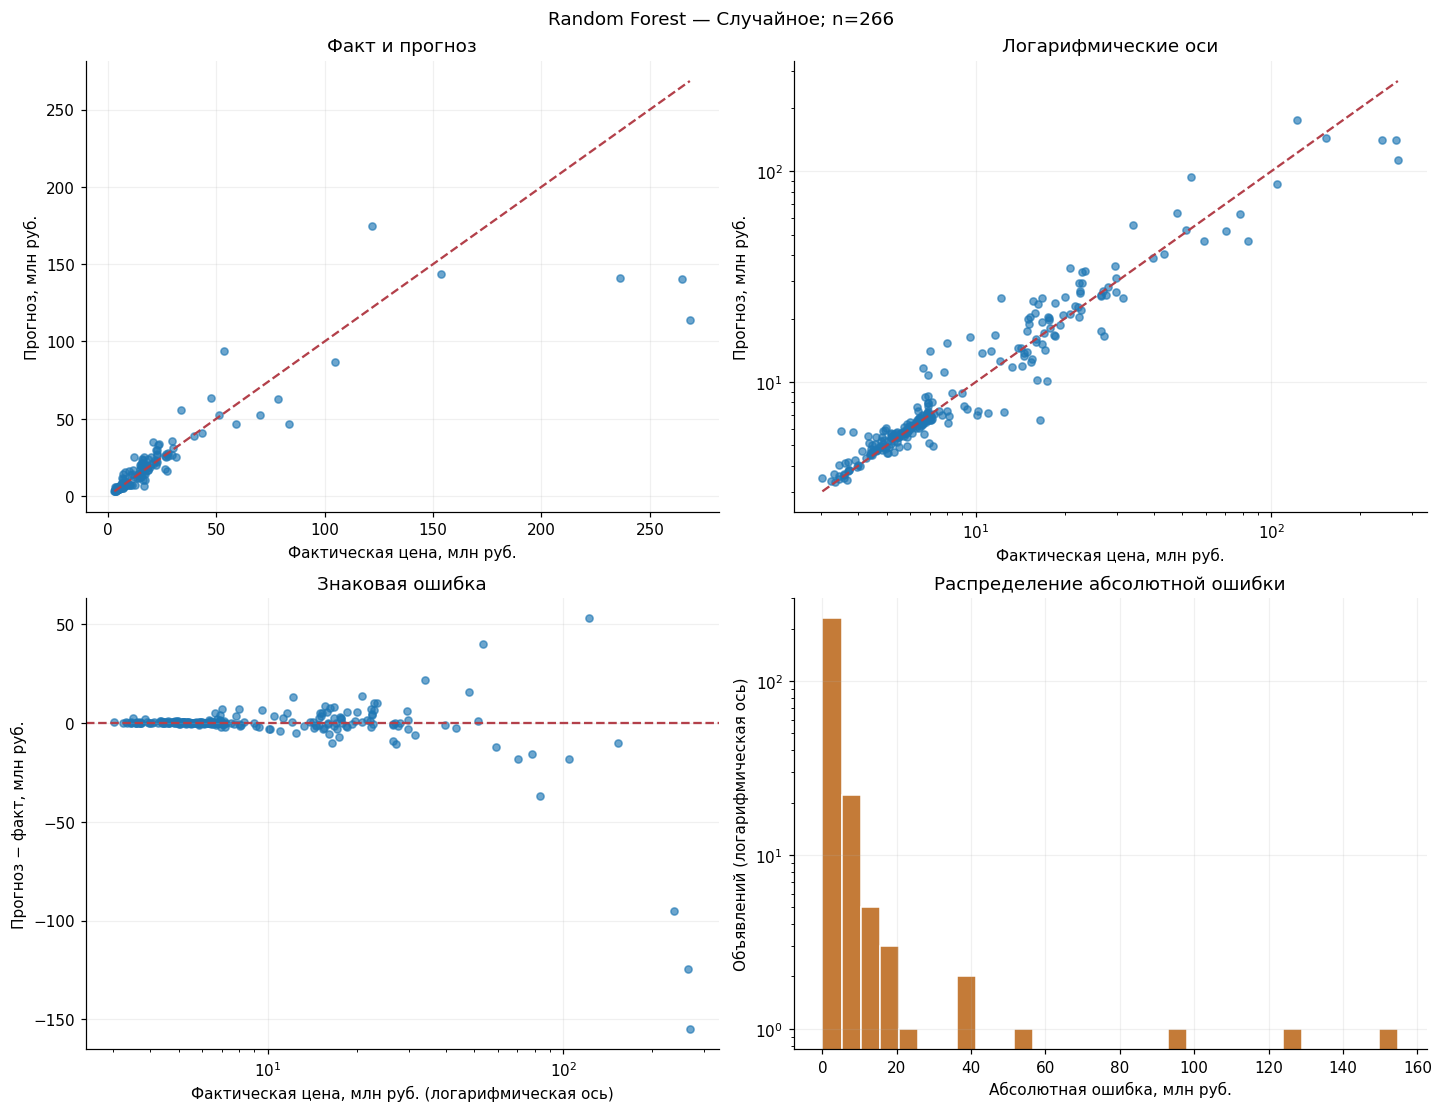

**Результат (Случайное).** Медианная абсолютная ошибка — 382,414 руб., 90-й перцентиль — 6,880,038 руб., максимум — 154,766,435 руб. Средняя знаковая ошибка — -918,187 руб. Разрыв между типичной и максимальной ошибкой показывает, почему одной средней метрики недостаточно.

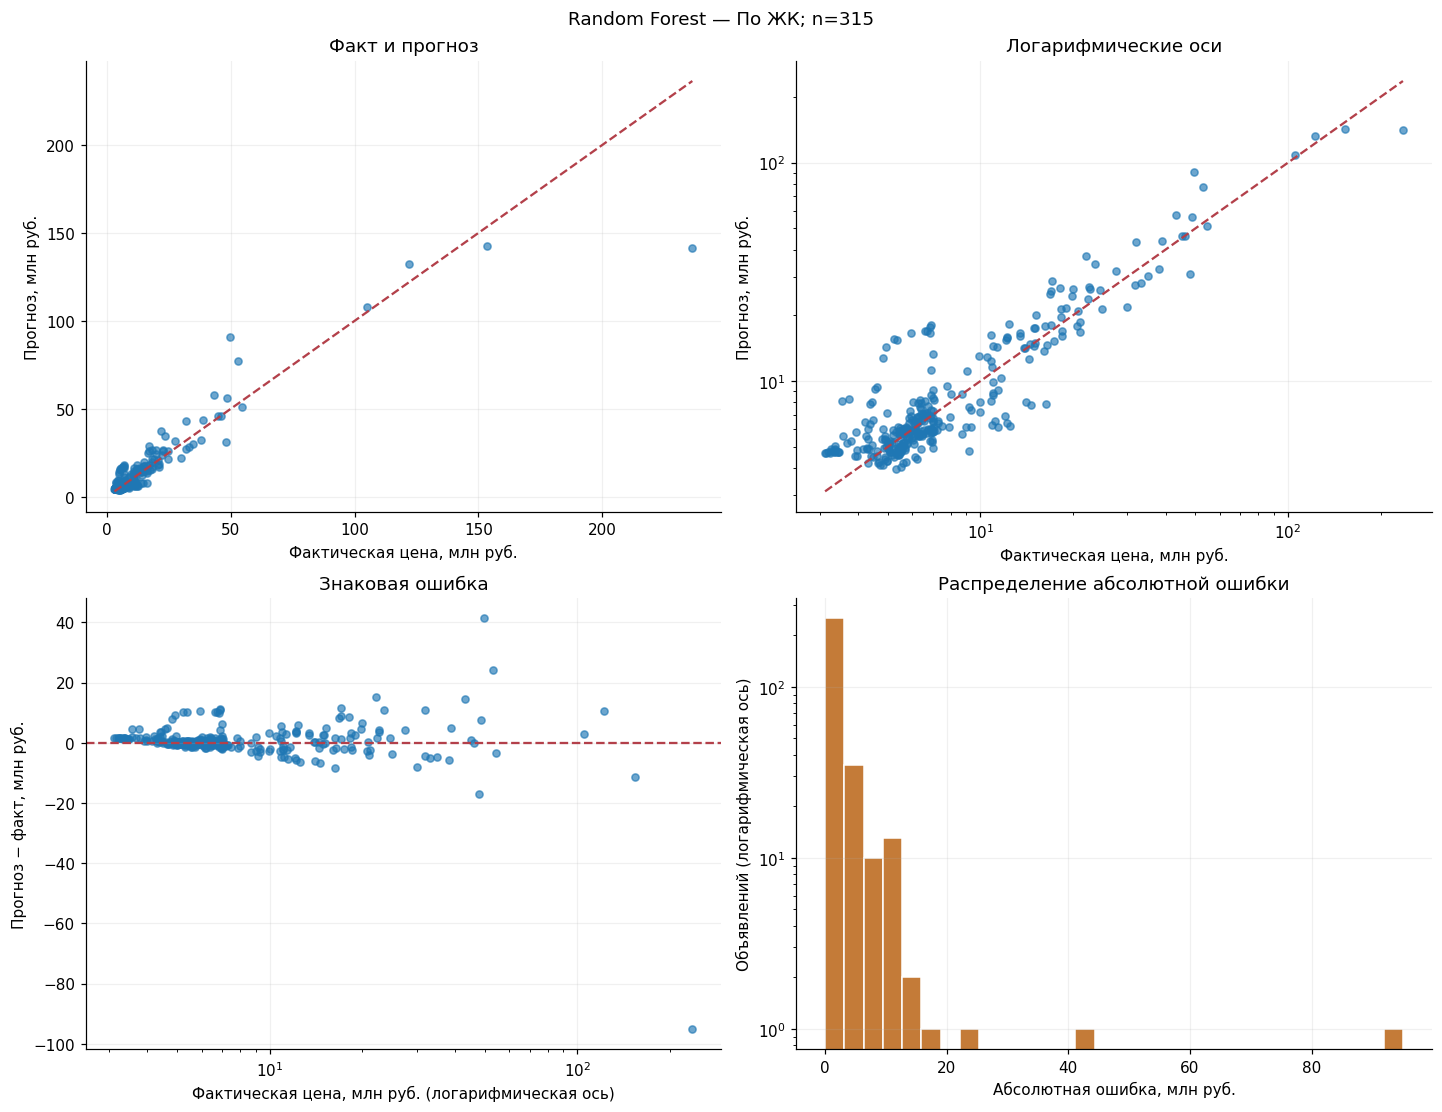

**Результат (По ЖК).** Медианная абсолютная ошибка — 1,091,351 руб., 90-й перцентиль — 5,983,637 руб., максимум — 95,036,158 руб. Средняя знаковая ошибка — +519,288 руб. Разрыв между типичной и максимальной ошибкой показывает, почему одной средней метрики недостаточно.

In [9]:
def plot_errors(scenario, result):
    actual = scenario["y_test"]
    predicted = result["predictions"][RF_NAME]
    residual = predicted - actual
    assert actual.gt(0).all() and predicted.gt(0).all()
    fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
    low = min(actual.min(), predicted.min()) / 1e6
    high = max(actual.max(), predicted.max()) / 1e6
    for axis, logarithmic in zip(axes[0], [False, True]):
        axis.scatter(actual / 1e6, predicted / 1e6, s=22, alpha=0.65)
        axis.plot([low, high], [low, high], color="#b3404a", linestyle="--")
        if logarithmic:
            axis.set_xscale("log")
            axis.set_yscale("log")
        axis.set(
            xlabel="Фактическая цена, млн руб.",
            ylabel="Прогноз, млн руб.",
            title="Логарифмические оси" if logarithmic else "Факт и прогноз",
        )
    axes[1, 0].scatter(actual / 1e6, residual / 1e6, s=22, alpha=0.65)
    axes[1, 0].axhline(0, color="#b3404a", linestyle="--")
    axes[1, 0].set_xscale("log")
    axes[1, 0].set(
        xlabel="Фактическая цена, млн руб. (логарифмическая ось)",
        ylabel="Прогноз − факт, млн руб.",
        title="Знаковая ошибка",
    )
    axes[1, 1].hist(
        abs(residual) / 1e6, bins=30, color="#c47b38", edgecolor="white"
    )
    axes[1, 1].set_yscale("log")
    axes[1, 1].set(
        xlabel="Абсолютная ошибка, млн руб.",
        ylabel="Объявлений (логарифмическая ось)",
        title="Распределение абсолютной ошибки",
    )
    fig.suptitle(f"Random Forest — {scenario['name']}; n={len(actual)}")
    plt.show()
    display(
        Markdown(
            f"**Результат ({scenario['name']}).** Медианная абсолютная ошибка — "
            f"{abs(residual).median():,.0f} руб., 90-й перцентиль — "
            f"{abs(residual).quantile(0.9):,.0f} руб., максимум — "
            f"{abs(residual).max():,.0f} руб. Средняя знаковая ошибка — "
            f"{residual.mean():+,.0f} руб. Разрыв между типичной и максимальной "
            "ошибкой показывает, почему одной средней метрики недостаточно."
        )
    )


for key in scenarios:
    plot_errors(scenarios[key], results[key])

### 7.1. Ошибки по группам

Для типов жилья, комнатности, районов и ценовых сегментов показываю число объявлений, MAE, RMSE и среднюю знаковую ошибку. Пропуски категорий не исключаются. Границы ценовых сегментов — квартильные значения **тренировочных** цен каждого сценария; в тесте использую интервалы `(-∞, Q1]`, `(Q1, Q2]`, `(Q2, Q3]`, `(Q3, +∞)`. Это диагностические группы по фактической цене, а не доступные модели входы. Малые группы, особенно пентхаус, не дают устойчивой оценки качества.

In [10]:
def error_metrics(actual, predicted):
    if len(actual) == 0:
        return {
            "n": 0,
            "MAE, руб.": np.nan,
            "RMSE, руб.": np.nan,
            "Средняя ошибка, руб.": np.nan,
        }
    return {
        "n": len(actual),
        "MAE, руб.": mean_absolute_error(actual, predicted),
        "RMSE, руб.": root_mean_squared_error(actual, predicted),
        "Средняя ошибка, руб.": float(np.mean(predicted - actual)),
    }


def group_errors(frame, column):
    rows = []
    for value, part in frame.groupby(
        column, dropna=False, observed=True, sort=True
    ):
        rows.append(
            {column: value, **error_metrics(part["Факт"], part["Прогноз"])}
        )
    return pd.DataFrame(rows).set_index(column)


error_frames, segment_tables = {}, {}
for key, scenario in scenarios.items():
    actual = scenario["y_test"]
    frame = df.loc[
        actual.index,
        [
            "Строка Excel",
            "Категория жилья",
            "Комнатность",
            "Район",
            "ЖК",
            "Потолки, м",
        ],
    ].copy()
    for column in ["Категория жилья", "Комнатность", "Район"]:
        frame[column] = frame[column].fillna("Нет данных")
    frame["Факт"] = actual
    frame["Прогноз"] = results[key]["predictions"][RF_NAME]
    quartiles = scenario["y_train"].quantile([0.25, 0.5, 0.75]).to_numpy()
    assert np.all(np.diff(quartiles) > 0)
    frame["Ценовой сегмент"] = pd.cut(
        actual,
        bins=[-np.inf, *quartiles, np.inf],
        labels=["Q1: до 25%", "Q2: 25–50%", "Q3: 50–75%", "Q4: выше 75%"],
    )
    error_frames[key] = frame
    display(Markdown(f"**{scenario['name']}: тренировочные границы, руб.**"))
    display(pd.Series(quartiles, index=["Q1", "Медиана", "Q3"], name="Цена"))
    segment_tables[key] = {}
    for column in [
        "Категория жилья",
        "Комнатность",
        "Район",
        "Ценовой сегмент",
    ]:
        table = group_errors(frame, column)
        assert table["n"].sum() == len(actual)
        segment_tables[key][column] = table
        display(Markdown(f"**Ошибки: {column}**"))
        display(table)
    largest = segment_tables[key]["Ценовой сегмент"]["MAE, руб."].idxmax()
    display(
        Markdown(
            f"**Результат.** Наибольшая MAE по ценовым квартилям — в сегменте "
            f"**{largest}**. Различия ошибок районов нельзя приписать только району: "
            "в них различаются площадь, ЖК и уровень цен. Для оценки надёжности "
            "важен столбец n; нулевой размер группы означает отсутствие оценки, "
            "а не нулевую ошибку."
        )
    )

**Случайное: тренировочные границы, руб.**

Q1         5,173,120.00
Медиана    6,321,675.00
Q3        12,183,750.00
Name: Цена, dtype: float64

**Ошибки: Категория жилья**

,n,"MAE, руб.","RMSE, руб.","Средняя ошибка, руб."
Категория жилья,,,,
Апартаменты,31,"1,818,795.06","3,906,792.95","-459,344.26"
Квартира,235,"3,901,807.71","15,661,941.67","-978,714.83"


**Ошибки: Комнатность**

...

**Ошибки: Район**

,n,"MAE, руб.","RMSE, руб.","Средняя ошибка, руб."
Район,,,,
Адмиралтейский,1,"6,456,822.79","6,456,822.79","6,456,822.79"
Василеостровский,21,"2,499,025.94","4,504,624.47","-623,528.77"
Выборгский,28,"5,102,038.48","9,770,591.85","2,395,013.64"
Кировский,3,"1,073,572.93","1,253,350.22","1,073,572.93"
Колпинский,5,"891,510.81","953,640.41","-416,063.24"
Красногвардейский,5,"457,529.13","491,568.13","457,529.13"
Красносельский,25,"922,738.22","1,562,446.49","-122,582.37"
Курортный,47,"1,210,150.73","2,066,202.63","-19,449.48"
Московский,21,"2,706,706.10","3,958,114.71","-1,032,994.85"


**Ошибки: Ценовой сегмент**

,n,"MAE, руб.","RMSE, руб.","Средняя ошибка, руб."
Ценовой сегмент,,,,
Q1: до 25%,71,"1,399,964.99","2,184,328.46","1,224,259.21"
Q2: 25–50%,96,"947,583.07","1,984,962.51","215,514.57"
Q3: 50–75%,92,"2,399,624.42","3,481,695.07","247,489.45"
Q4: выше 75%,56,"7,583,762.00","15,546,321.59","592,764.99"


**Результат.** Наибольшая MAE по ценовым квартилям — в сегменте **Q4: выше 75%**. Различия ошибок районов нельзя приписать только району: в них различаются площадь, ЖК и уровень цен. Для оценки надёжности важен столбец n; нулевой размер группы означает отсутствие оценки, а не нулевую ошибку.

### 7.2. Дорогой хвост, потолки 7 м и неизвестные ЖК

Дорогой хвост определяю заранее выбранным правилом **выше 95-го перцентиля тренировочной цены**, отдельно для каждого сценария. Показываю также ошибку на остальных объектах и долю хвоста в сумме абсолютных ошибок. Два объявления с потолками 7 м не удалялись и не переносились между частями. Для неизвестных ЖК привожу отдельную строку, даже если в тесте их нет.

In [11]:
tail_tables = {}
for key, scenario in scenarios.items():
    frame = error_frames[key]
    threshold = scenario["y_train"].quantile(0.95)
    tail = frame["Факт"].gt(threshold)
    masks = {
        "Все тестовые объекты": pd.Series(True, index=frame.index),
        "Дорогой хвост > train Q95": tail,
        "Остальные ≤ train Q95": ~tail,
        "Потолки 7 м": frame["Потолки, м"].eq(7).fillna(False),
        "ЖК неизвестен": frame["ЖК"].isna(),
    }
    table = pd.DataFrame(
        {
            name: error_metrics(
                frame.loc[mask, "Факт"], frame.loc[mask, "Прогноз"]
            )
            for name, mask in masks.items()
        }
    ).T
    table["n"] = table["n"].astype(int)
    tail_tables[key] = table
    display(
        Markdown(f"**{scenario['name']}: train Q95 = {threshold:,.0f} руб.**")
    )
    display(table)
    ceilings = masks["Потолки 7 м"]
    if ceilings.any():
        display(
            frame.loc[ceilings].assign(
                **{"Ошибка, руб.": frame["Прогноз"] - frame["Факт"]}
            )
        )
    tail_share = (
        (frame.loc[tail, "Прогноз"] - frame.loc[tail, "Факт"]).abs().sum()
    )
    tail_share /= (frame["Прогноз"] - frame["Факт"]).abs().sum()
    display(
        Markdown(
            f"**Результат.** Хвост: {int(tail.sum())} из {len(frame)} объектов, "
            f"{tail_share:.1%} суммы абсолютных ошибок. Объектов с потолками 7 м "
            f"в тесте: {int(ceilings.sum())}; при n=0 тестовая оценка невозможна, "
            "при n=1–2 она описывает лишь эти объявления."
        )
    )

**Случайное: train Q95 = 36,396,151 руб.**

,n,"MAE, руб.","RMSE, руб.","Средняя ошибка, руб."
Все тестовые объекты,266,"3,659,050.59","14,781,340.09","-918,186.68"
Дорогой хвост > train Q95,15,"39,899,339.92","60,927,095.07","-25,326,268.23"
Остальные ≤ train Q95,251,"1,493,296.25","3,115,408.47","540,463.61"
Потолки 7 м,0,NaN,NaN,NaN
ЖК неизвестен,2,"1,506,241.54","1,568,086.31","1,506,241.54"


**Результат.** Хвост: 15 из 266 объектов, 61.5% суммы абсолютных ошибок. Объектов с потолками 7 м в тесте: 0; при n=0 тестовая оценка невозможна, при n=1–2 она описывает лишь эти объявления.

**По ЖК: train Q95 = 37,038,941 руб.**

,n,"MAE, руб.","RMSE, руб.","Средняя ошибка, руб."
Все тестовые объекты,315,"2,653,401.93","6,984,514.81","519,287.84"
Дорогой хвост > train Q95,14,"17,124,015.61","29,517,982.62","-1,816,328.31"
Остальные ≤ train Q95,301,"1,980,350.13","3,244,431.82","627,921.15"
Потолки 7 м,0,NaN,NaN,NaN
ЖК неизвестен,0,NaN,NaN,NaN


**Результат.** Хвост: 14 из 315 объектов, 28.7% суммы абсолютных ошибок. Объектов с потолками 7 м в тесте: 0; при n=0 тестовая оценка невозможна, при n=1–2 она описывает лишь эти объявления.

### 7.3. Чувствительность к признаку потолков на тренировочной CV

**Наблюдение по хвосту.** В основном тесте 15 дорогих объявлений дают 61,5% суммы абсолютных ошибок; их MAE 39,899 млн руб. против 1,493 млн у остальных. Средняя ошибка хвоста отрицательна (−25,326 млн руб.): лес в среднем недооценивает этот сегмент. В групповом тесте хвост даёт 28,7% общей абсолютной ошибки, что помогает объяснить меньшую итоговую MAE при худшей медианной ошибке. Обоих объектов с потолками 7 м нет ни в одном тесте: оценить их тестовую ошибку нельзя.

Сохраняю выбранные параметры леса каждого сценария и сравниваю полный набор с набором без `Потолки, м` на тех же пяти тренировочных фолдах. Все преобразования обучаются заново. Это удаление всего признака и его индикатора, а не удаление двух объектов. Тест не используется. Поскольку параметры уже выбирались на этих фолдах с потолками, проверка описательная; она не является независимой оценкой пользы признака и не меняет финальную модель. Здесь SD — выборочное стандартное отклонение (`ddof=1`); таблицы GridSearchCV выше используют `ddof=0`.

In [12]:
ablation_tables = {}
for key, scenario in scenarios.items():
    selected = results[key]["models"][RF_NAME]
    without = make_pipeline(
        clone(selected.named_steps["model"]),
        [feature for feature in FEATURES if feature != "Потолки, м"],
    )
    fold_results = {}
    with parallel_config(backend="loky", inner_max_num_threads=1):
        for name, estimator in [
            ("С потолками", clone(selected)),
            ("Без потолков", without),
        ]:
            scores = cross_validate(
                estimator,
                scenario["X_train"],
                scenario["y_train"],
                cv=scenario["folds"],
                scoring=SCORING,
                n_jobs=2,
                error_score="raise",
            )
            fold_results[name] = -scores["test_mae"]
    table = pd.DataFrame(
        fold_results, index=pd.Index(range(1, 6), name="Фолд")
    )
    table["Без − с, руб."] = table["Без потолков"] - table["С потолками"]
    ablation_tables[key] = table
    display(Markdown(f"**{scenario['name']}: MAE, руб.**"))
    display(table)
    display(
        table.agg(["mean", "std"]).rename(
            index={"mean": "Среднее", "std": "SD"}
        )
    )
    delta = table["Без − с, руб."].mean()
    direction = "увеличивает" if delta > 0 else "уменьшает"
    display(
        Markdown(
            f"**Результат.** Исключение потолков {direction} среднюю CV MAE на "
            f"{abs(delta):,.0f} руб.; положительный знак разности "
            "означает преимущество "
            "модели с потолками. Высота может быть связана с классом дома и ЖК, "
            "поэтому это не причинный эффект дополнительных метров потолка."
        )
    )

**Случайное: MAE, руб.**

,С потолками,Без потолков,"Без − с, руб."
Фолд,,,
1,"1,894,727.98","1,907,441.57","12,713.59"
2,"1,575,293.80","1,532,069.29","-43,224.51"
3,"2,826,547.46","2,852,198.14","25,650.68"
4,"2,872,374.00","2,923,827.31","51,453.31"
5,"1,990,738.07","2,054,788.54","64,050.47"


,С потолками,Без потолков,"Без − с, руб."
Среднее,"2,231,936.26","2,254,064.97","22,128.71"
SD,"584,548.61","609,811.76","41,801.49"


**Результат.** Исключение потолков увеличивает среднюю CV MAE на 22,129 руб.; положительный знак разности означает преимущество модели с потолками. Высота может быть связана с классом дома и ЖК, поэтому это не причинный эффект дополнительных метров потолка.

**По ЖК: MAE, руб.**

,С потолками,Без потолков,"Без − с, руб."
Фолд,,,
1,"1,920,060.05","2,068,045.89","147,985.84"
2,"3,247,581.02","3,261,714.29","14,133.27"
3,"3,512,309.46","3,455,476.28","-56,833.18"
4,"6,069,748.69","6,261,026.75","191,278.06"
5,"2,261,298.22","2,353,139.11","91,840.89"


,С потолками,Без потолков,"Без − с, руб."
Среднее,"3,402,199.49","3,479,880.46","77,680.98"
SD,"1,631,735.49","1,661,760.33","100,224.68"


**Результат.** Исключение потолков увеличивает среднюю CV MAE на 77,681 руб.; положительный знак разности означает преимущество модели с потолками. Высота может быть связана с классом дома и ЖК, поэтому это не причинный эффект дополнительных метров потолка.

## 8. Глобальная интерпретация основного Random Forest

**Вывод проверки потолков.** Без этого признака средняя CV MAE увеличилась на 22,1 тыс. руб. в основном сценарии и на 77,7 тыс. руб. в групповом. На одном из пяти фолдов каждого сценария удаление, наоборот, уменьшает ошибку; эффект невелик относительно общего масштаба MAE. Это не позволяет отдельно оценить полезность двух редких значений 7 м.

Permutation importance рассчитывается по **исходным 23 признакам**: перемешивается столбец тестовой таблицы до применения Pipeline. Критерий — отрицательная MAE, 10 повторов, seed 42. Положительная важность равна увеличению MAE при перемешивании; отрицательная означает, что перемешивание в среднем немного помогло. Полосы ошибки показывают SD по перестановкам, а не неопределённость обобщения модели.

Перестановка площади сохраняет её пропуски вместе со значениями; кодирование и заполнение не переобучаются. Коррелирующие признаки могут заменять друг друга (например, площади, комнатность и ЖК), а перестановки способны создавать нетипичные сочетания. Важность описывает использование информации моделью и не доказывает причинного влияния на цену. Тестовая интерпретация не используется для дальнейшего выбора модели или признаков.

,"Рост MAE, руб.","SD, руб."
Признак,,
"Общая площадь, м²","11,122,238.70","427,917.39"
Район,"472,636.78","43,939.46"
Комнат,"358,722.92","36,116.60"
"Потолки, м","312,020.06","39,692.28"
Этажность,"279,539.02","42,415.40"
ЖК,"223,889.15","14,003.34"
"Отделка, категория","119,622.18","51,900.28"
Метро,"113,708.40","27,299.11"
Доля этажа,"92,600.67","23,506.64"


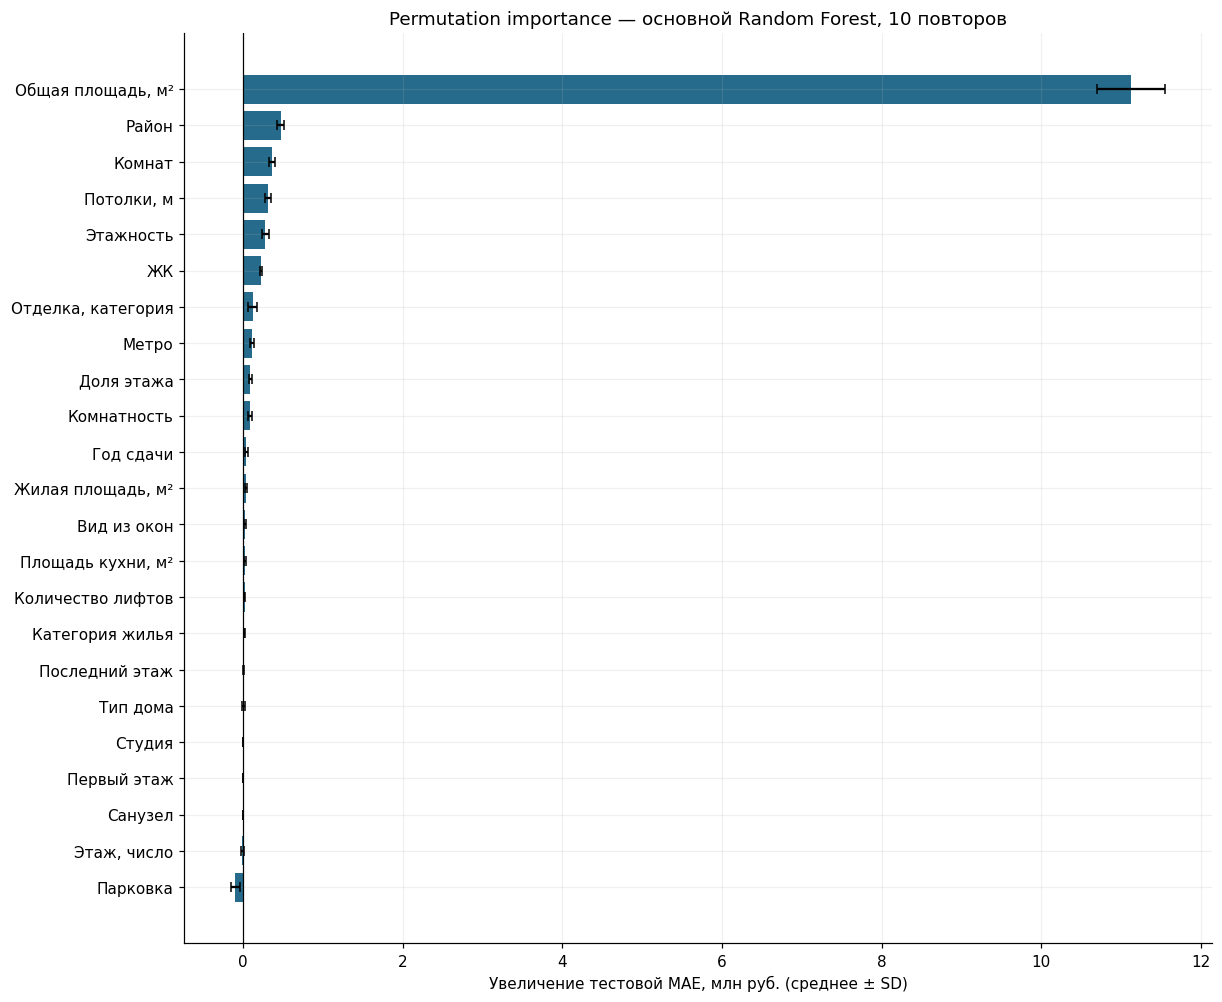

**Результат.** Три наибольшие важности: **Общая площадь, м²** (11,122,239 руб.), **Район** (472,637 руб.), **Комнат** (358,723 руб.). Эти признаки сильнее остальных влияют на точность данного леса в данном тесте. Малый прирост MAE не доказывает бесполезность признака: его информацию могут дублировать другие входы.

In [13]:
main_scenario = scenarios["random"]
main_forest = results["random"]["models"][RF_NAME]
with parallel_config(backend="loky", inner_max_num_threads=1):
    permutation = permutation_importance(
        main_forest,
        main_scenario["X_test"],
        main_scenario["y_test"],
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=SEED,
        n_jobs=2,
    )
importance = (
    pd.DataFrame(
        {
            "Признак": FEATURES,
            "Рост MAE, руб.": permutation.importances_mean,
            "SD, руб.": permutation.importances_std,
        }
    )
    .set_index("Признак")
    .sort_values("Рост MAE, руб.", ascending=False)
)
display(importance)
plot_table = importance.iloc[::-1]
fig, axis = plt.subplots(figsize=(11, 9), layout="constrained")
axis.barh(
    plot_table.index,
    plot_table["Рост MAE, руб."] / 1e6,
    xerr=plot_table["SD, руб."] / 1e6,
    color="#266b8b",
    capsize=3,
)
axis.axvline(0, color="black", linewidth=0.8)
axis.set(
    xlabel="Увеличение тестовой MAE, млн руб. (среднее ± SD)",
    title="Permutation importance — основной Random Forest, 10 повторов",
)
plt.show()
display(
    Markdown(
        "**Результат.** Три наибольшие важности: "
        + ", ".join(
            f"**{name}** ({row['Рост MAE, руб.']:,.0f} руб.)"
            for name, row in importance.head(3).iterrows()
        )
        + ". Эти признаки сильнее остальных влияют на точность данного леса "
        "в данном тесте. Малый прирост MAE не доказывает бесполезность признака: "
        "его информацию могут дублировать другие входы."
    )
)

## 9. Локальная интерпретация: три разных объекта

**Глобальный вывод.** Лес прежде всего использует общую площадь: её перестановка увеличивает MAE на 11,122 млн руб. Район и число комнат дают гораздо меньшие, но положительные приросты (473 и 359 тыс. руб.). Это согласуется с предметным смыслом размера и местоположения жилья. Для парковки средняя важность отрицательна (−95 тыс. руб.): в этой выборке её перемешивание помогло, что может указывать на нестабильное использование редких сведений. По тестовой важности признаки не удаляю.

Выбираю тестовые объекты по фиксированному правилу: ближайший к медианной фактической цене теста, самый дорогой из оставшихся, затем объект с наибольшей абсолютной ошибкой среди остальных. При равенстве используется первый индекс в текущем порядке теста. Это иллюстрации разных режимов, а не репрезентативная выборка объяснений.

Использую [SHAP TreeExplainer](https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html) с `feature_perturbation="tree_path_dependent"` и `model_output="raw"`. Лес обучен на рублях, поэтому базовое значение и вклады тоже в рублях. Фоновое распределение определяется числами тренировочных объектов на путях деревьев; отдельная тестовая фоновая выборка не передаётся.

Вклады One-Hot столбцов и индикаторов пропусков **суммируются по исходным признакам**. Это агрегация объяснения закодированной модели, а не заново вычисленные Shapley-значения игры с объединёнными признаками. Проверяю: база + все вклады = прогноз, с допустимой численной погрешностью 1 рубль. Waterfall строится в matplotlib по агрегированным SHAP-вкладам: начиная с базы, последовательно добавляю десять крупнейших по модулю вкладов и сумму остальных. Значения справа и ось выражены в рублях; характеристики объекта приведены отдельно. Положительные вклады повышают прогноз относительно базы, отрицательные — понижают. Вклады не являются причинными эффектами.

,Объект,Строка Excel,"База, руб.","Сумма вкладов, руб.","База + вклады, руб.","Прогноз, руб.","Расхождение, руб."
0,Около медианы,298,"11,898,690.00","-5,335,615.79","6,563,074.21","6,563,074.21",0.00
1,Самый дорогой из оставшихся,942,"11,898,690.00","101,774,875.00","113,673,565.00","113,673,565.00",-0.00
2,Максимальная ошибка среди остальных,941,"11,898,690.00","128,496,132.57","140,394,822.58","140,394,822.57",0.00


### 9.1. Около медианы — строка Excel 298

Факт: **6,600,254 руб.**, прогноз: **6,563,074 руб.**, ошибка: **-37,180 руб.**

,Значение
"Общая площадь, м²",34.59
"Жилая площадь, м²",14.20
"Площадь кухни, м²",10.30
"Потолки, м",2.75
"Этаж, число",1.00
Этажность,5.00
Доля этажа,0.20
Комнат,1.00
Год сдачи,"2,024.00"
Студия,0.00


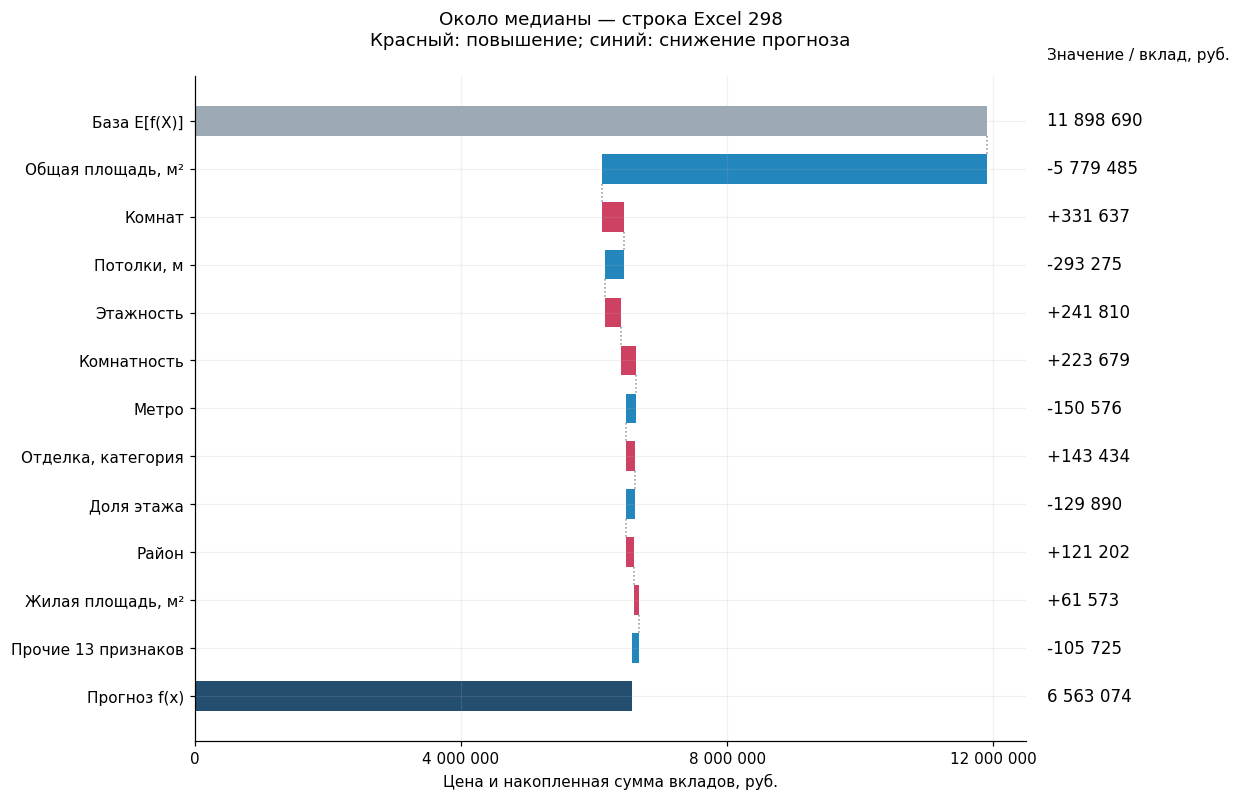

**Объяснение модели.** Крупнейшие по модулю вклады: Общая площадь, м²: -5,779,485 руб; Комнат: +331,637 руб; Потолки, м: -293,275 руб. Это отклонения от общей базы ансамбля с учётом других признаков, а не рыночная надбавка за отдельную характеристику.

### 9.2. Самый дорогой из оставшихся — строка Excel 942

Факт: **268,440,000 руб.**, прогноз: **113,673,565 руб.**, ошибка: **-154,766,435 руб.**

,Значение
"Общая площадь, м²",227.95
"Жилая площадь, м²",NaN
"Площадь кухни, м²",NaN
"Потолки, м",3.28
"Этаж, число",7.00
Этажность,7.00
Доля этажа,1.00
Комнат,3.00
Год сдачи,"2,022.00"
Студия,0.00


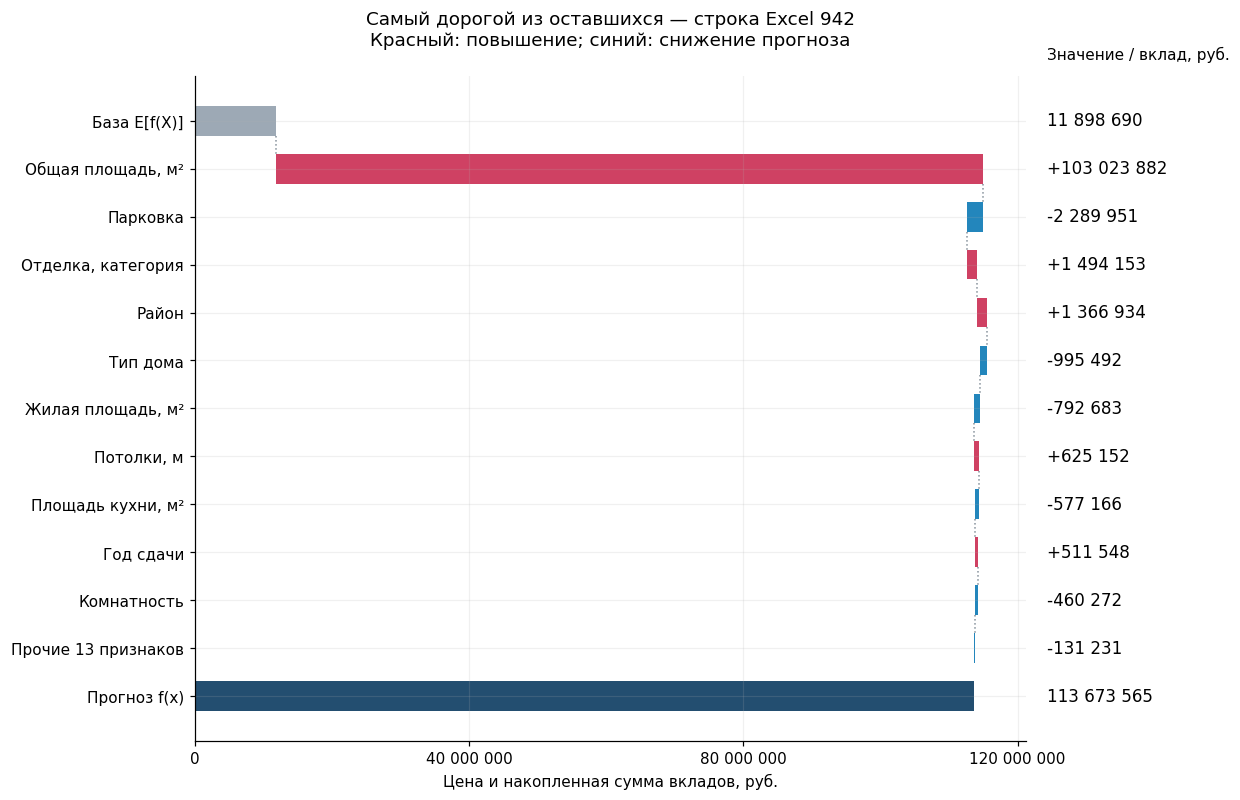

**Объяснение модели.** Крупнейшие по модулю вклады: Общая площадь, м²: +103,023,882 руб; Парковка: -2,289,951 руб; Отделка, категория: +1,494,153 руб. Это отклонения от общей базы ансамбля с учётом других признаков, а не рыночная надбавка за отдельную характеристику.

### 9.3. Максимальная ошибка среди остальных — строка Excel 941

Факт: **264,770,000 руб.**, прогноз: **140,394,823 руб.**, ошибка: **-124,375,177 руб.**

,Значение
"Общая площадь, м²",246.07
"Жилая площадь, м²",NaN
"Площадь кухни, м²",NaN
"Потолки, м",3.28
"Этаж, число",7.00
Этажность,7.00
Доля этажа,1.00
Комнат,4.00
Год сдачи,"2,022.00"
Студия,0.00


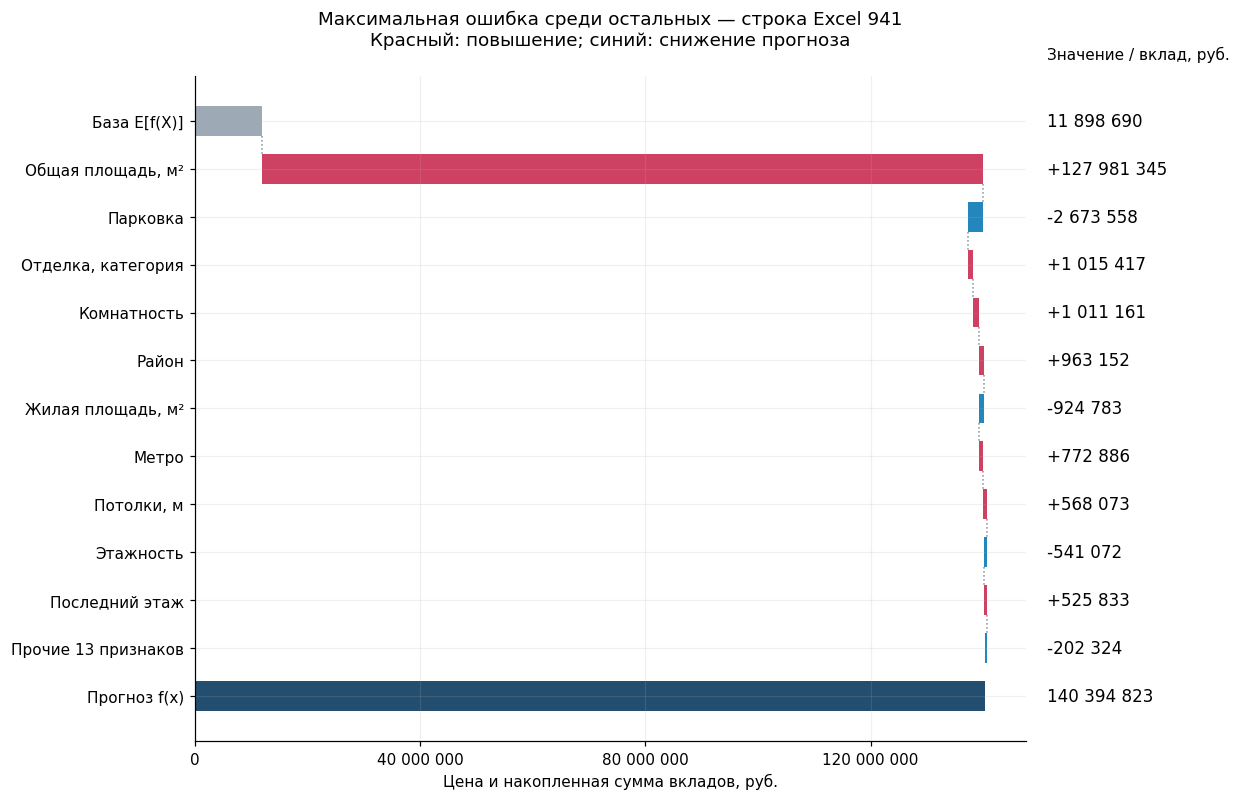

**Объяснение модели.** Крупнейшие по модулю вклады: Общая площадь, м²: +127,981,345 руб; Парковка: -2,673,558 руб; Отделка, категория: +1,015,417 руб. Это отклонения от общей базы ансамбля с учётом других признаков, а не рыночная надбавка за отдельную характеристику.

In [14]:
actual = main_scenario["y_test"]
predicted = results["random"]["predictions"][RF_NAME]
median_id = (actual - actual.median()).abs().idxmin()
expensive_id = actual.drop(index=median_id).idxmax()
error_id = (
    (predicted - actual).abs().drop(index=[median_id, expensive_id]).idxmax()
)
selected_ids = [median_id, expensive_id, error_id]
assert len(set(selected_ids)) == 3
selection_labels = [
    "Около медианы",
    "Самый дорогой из оставшихся",
    "Максимальная ошибка среди остальных",
]
local_x = main_scenario["X_test"].loc[selected_ids]
preprocessor = main_forest.named_steps["preprocess"]
encoded_x = preprocessor.transform(local_x)
encoded_names = preprocessor.get_feature_names_out()


def original_feature(encoded_name):
    """Однозначная привязка каждого выходного столбца к исходному признаку."""
    block, name = encoded_name.split("__", 1)
    if block == "num":
        name = name.removeprefix("missingindicator_")
        assert name in NUMERIC
        return name
    if block == "bin":
        assert name in BINARY
        return name
    assert block == "cat"
    matches = [
        feature for feature in CATEGORICAL if name.startswith(feature + "_")
    ]
    assert len(matches) == 1, (encoded_name, matches)
    return matches[0]


owners = [original_feature(name) for name in encoded_names]
assert set(owners) == set(FEATURES)
assert len(owners) == encoded_x.shape[1]
explainer = shap.TreeExplainer(
    main_forest.named_steps["model"],
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)
explanation = explainer(encoded_x, check_additivity=True)
grouped_values = np.column_stack(
    [
        explanation.values[:, np.array(owners) == feature].sum(axis=1)
        for feature in FEATURES
    ]
)
base_values = np.asarray(explanation.base_values).reshape(-1)
reconstructed = base_values + grouped_values.sum(axis=1)
local_predictions = main_forest.predict(local_x)
np.testing.assert_allclose(reconstructed, local_predictions, rtol=0, atol=1)
np.testing.assert_allclose(
    base_values + explanation.values.sum(axis=1),
    local_predictions,
    rtol=0,
    atol=1,
)
additivity = pd.DataFrame(
    {
        "Объект": selection_labels,
        "Строка Excel": df.loc[selected_ids, "Строка Excel"].to_numpy(),
        "База, руб.": base_values,
        "Сумма вкладов, руб.": grouped_values.sum(axis=1),
        "База + вклады, руб.": reconstructed,
        "Прогноз, руб.": local_predictions,
        "Расхождение, руб.": reconstructed - local_predictions,
    }
)
display(additivity)


def plot_shap_waterfall(values, base, names, title):
    """Waterfall в рублях; подписи вкладов вынесены в отдельную колонку."""
    order = np.argsort(-np.abs(values), kind="stable")
    top, remainder = order[:10], order[10:]
    contributions = [*values[top], values[remainder].sum()]
    labels = [names[index] for index in top]
    labels.append(f"Прочие {len(remainder)} признаков")
    labels = ["База E[f(X)]", *labels, "Прогноз f(x)"]
    figure, axis = plt.subplots(figsize=(14, 8.4))
    figure.subplots_adjust(left=0.25, right=0.79, top=0.84, bottom=0.12)
    axis.barh(0, base, color="#9da9b5", height=0.62)
    numbers = [f"{base:,.0f}"]
    running = base
    for position, contribution in enumerate(contributions, 1):
        following = running + contribution
        color = "#cf4163" if contribution >= 0 else "#2386bc"
        axis.barh(
            position,
            abs(contribution),
            left=min(running, following),
            color=color,
            height=0.62,
        )
        axis.plot(
            [running, running],
            [position - 1 + 0.31, position - 0.31],
            color="#85909a",
            linestyle=":",
            linewidth=1,
        )
        numbers.append(f"{contribution:+,.0f}")
        running = following
    axis.barh(len(labels) - 1, running, color="#234e70", height=0.62)
    numbers.append(f"{running:,.0f}")
    for position, number in enumerate(numbers):
        axis.text(
            1.025,
            position,
            number.replace(",", " "),
            transform=axis.get_yaxis_transform(),
            va="center",
            fontsize=11,
        )
    axis.set_yticks(range(len(labels)), labels)
    axis.invert_yaxis()
    axis.xaxis.set_major_locator(MaxNLocator(nbins=4))
    axis.xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", " "))
    )
    axis.set_xlabel("Цена и накопленная сумма вкладов, руб.")
    axis.set_title(
        title + "\nКрасный: повышение; синий: снижение прогноза", pad=20
    )
    axis.text(
        1.025,
        1.025,
        "Значение / вклад, руб.",
        transform=axis.transAxes,
        fontsize=10,
    )
    plt.show()


for position, (row_id, label) in enumerate(
    zip(selected_ids, selection_labels)
):
    display(
        Markdown(
            f"### 9.{position + 1}. {label} — "
            f"строка Excel {df.loc[row_id, 'Строка Excel']}\n\n"
            f"Факт: **{actual.loc[row_id]:,.0f} руб.**, "
            f"прогноз: **{predicted.loc[row_id]:,.0f} руб.**, "
            f"ошибка: **{predicted.loc[row_id] - actual.loc[row_id]:+,.0f} руб.**"
        )
    )
    display(local_x.loc[row_id].rename("Значение").to_frame())
    contributions = pd.Series(grouped_values[position], index=FEATURES)
    plot_shap_waterfall(
        grouped_values[position],
        base_values[position],
        FEATURES,
        f"{label} — строка Excel {df.loc[row_id, 'Строка Excel']}",
    )
    strongest = contributions.abs().nlargest(3).index
    description = "; ".join(
        f"{name}: {contributions[name]:+,.0f} руб" for name in strongest
    )
    display(
        Markdown(
            f"**Объяснение модели.** Крупнейшие по модулю вклады: {description}. "
            "Это отклонения от общей базы ансамбля с учётом других признаков, "
            "а не рыночная надбавка за отдельную характеристику."
        )
    )

## 10. Итоги и ограничения

**Вывод локальных объяснений.** Для однокомнатной квартиры 34,59 м² в «Зелёном квартале» (строка Excel 298) прогноз 6,563 млн руб. близок к факту 6,600 млн. Небольшая площадь уменьшает прогноз относительно базы ансамбля 11,899 млн руб. Два выбранных дорогих объекта — разные объявления в ЖК «Приоритет», 227,95 и 246,07 м² (строки 942 и 941). Большая площадь сильно повышает их прогнозы, но лес всё равно недооценивает фактические 268,440 и 264,770 млн руб. на 154,766 и 124,375 млн. Это показывает пределы оценки редкого премиального сегмента по имеющимся характеристикам. Отрицательные вклады парковки у этих объектов относятся к **отсутствию сведений**, а не доказывают отсутствие самой парковки или рыночную скидку за неё. Два объяснения из одного ЖК не дают независимого подтверждения закономерности.

Ниже результаты подставляются из выполненных расчётов, без ручного назначения победителя. Улучшение расширенного набора и леса проверяется относительно честного Ridge с тремя площадями на тех же строках; прежний результат с нормализацией до разбиения не используется как численный ориентир.

In [15]:
for key, scenario in scenarios.items():
    result = results[key]
    winner = result["winner"]
    table = result["test"]
    minimal = table.loc[SMALL_NAME, "Test MAE, руб."]
    full = table.loc[FULL_NAME, "Test MAE, руб."]
    forest = table.loc[RF_NAME, "Test MAE, руб."]
    full_verdict = "подтверждено" if full < minimal else "не подтверждено"
    forest_verdict = "подтверждено" if forest < minimal else "не подтверждено"
    display(
        Markdown(
            f"- **{scenario['name']}:** победитель по CV — {winner}; "
            f"тестовая MAE {table.loc[winner, 'Test MAE, руб.']:,.0f} руб. "
            f"Снижение MAE расширенного Ridge относительно трёх площадей "
            f"{full_verdict} ({1-full/minimal:+.1%}); для леса — "
            f"{forest_verdict} ({1-forest/minimal:+.1%}). "
            "Это результаты конкретного разбиения, а не доказательство "
            "статистической значимости или гарантированного улучшения на рынке."
        )
    )

assert X.columns.tolist() == FEATURES
assert set(X.columns).isdisjoint(FORBIDDEN)
assert len(df) == 1328 and df[LINK].is_unique
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash
assert all(
    len(result["searches"][RF_NAME].cv_results_["params"]) == 20
    for result in results.values()
)
assert all(len(result["test"]) == 5 for result in results.values())
assert scenarios["group"]["overlap"] == 0
assert additivity["Расхождение, руб."].abs().max() < 1
print(
    "Проверки пройдены: данные сохранены, утечки по URL/ЖК исключены, "
    "запрещённых входов нет, оба поиска завершены, SHAP аддитивен."
)

- **Случайное:** победитель по CV — Random Forest; тестовая MAE 3,659,051 руб. Снижение MAE расширенного Ridge относительно трёх площадей подтверждено (+46.2%); для леса — подтверждено (+31.0%). Это результаты конкретного разбиения, а не доказательство статистической значимости или гарантированного улучшения на рынке.

- **По ЖК:** победитель по CV — Random Forest; тестовая MAE 2,653,402 руб. Снижение MAE расширенного Ridge относительно трёх площадей подтверждено (+36.7%); для леса — подтверждено (+28.5%). Это результаты конкретного разбиения, а не доказательство статистической значимости или гарантированного улучшения на рынке.

Проверки пройдены: данные сохранены, утечки по URL/ЖК исключены, запрещённых входов нет, оба поиска завершены, SHAP аддитивен.


**Предметная интерпретация.** Площадь и местоположение описывают размер и контекст предложения, а ЖК, отделка и потолки могут косвенно отражать класс проекта. Поэтому использование этих характеристик моделью разумно, но взаимосвязи между ними не позволяют трактовать важность или SHAP как изменение цены при вмешательстве в один признак. Лес усредняет наблюдавшиеся цены и плохо приспособлен к экстраполяции уникальных дорогих объектов; ошибки хвоста требуют отдельного внимания.

**Ограничения.** Это исторические цены объявлений декабря 2024 года, а не сделки и не текущая рыночная оценка. Дедупликация по URL не гарантирует отсутствие одной квартиры под разными ссылками. Единичный пентхаус и малые группы не позволяют надёжно оценить качество на редких типах жилья. Отсутствующие ЖК объединены условно, а текстовые признаки пока разобраны лишь частично. Подбор ограничен заданным пространством и одной схемой разбиения; разброс CV и перестановок не заменяет внешнюю проверку. Весь набор уже рассматривался в EDA, поэтому тест отложен для обучения, но не был полностью скрыт при исследовании. Следующий необходимый шаг перед применением — новые данные с датами и независимая проверка на актуальном рынке.

### Покрытие критериев ДЗ 2

| Критерий | Где выполнен |
|---|---|
| Разделение train/test, воспроизводимость, отсутствие пересечений | Разделы 1–3; seed 42, URL и групповые проверки |
| Константные прогнозы | Разделы 4–6; среднее и медиана внутри каждого фолда |
| Простая модель и обоснованная предобработка | Раздел 4; два набора Ridge, Pipeline, два варианта цели |
| Оценка качества на отложенной выборке | Разделы 5–6; MAE/RMSE в рублях, победитель фиксируется по CV |
| Ансамбль и подбор гиперпараметров | Разделы 4–6; RandomizedSearchCV, 20 комбинаций, refit по MAE |
| Обучение с лучшими параметрами | `best_estimator_` переобучен на всей соответствующей тренировочной части |
| Анализ ошибок и устойчивости | Раздел 7; графики, группы с n, дорогой хвост и потолки |
| Глобальная интерпретация и визуализация | Раздел 8; permutation importance исходных признаков |
| Локальная интерпретация и визуализация | Раздел 9; три waterfall SHAP в рублях, проверка суммы вкладов |
| Предметная оценка и обоснования решений | Markdown до и после блоков; раздел 10 |
| Читаемый код и самостоятельный запуск | Именованные функции, относительные пути, отдельные закреплённые зависимости |

Таблица показывает выполненные части работы и не является самостоятельным выставлением оценки.